# II. Dự đoán giá nhà

**Dataset:** `hanoi_hcm_real_estate.csv` (https://huggingface.co/datasets/SpringWang08/hanoi-hcmc-real-estate)

Bài toán là **Regression**, biến cần dự đoán là `price_vnd`.

Các **features** là những thông tin đầu vào dùng để dự đoán giá nhà. Trong bài này sử dụng các đặc trưng chính:

- `area`: diện tích bất động sản (m²).
- `bedrooms`: số phòng ngủ.
- `toilets`: số phòng vệ sinh.
- `Total Floors`: tổng số tầng.
- `Type of House`: loại bất động sản như nhà mặt tiền, nhà hẻm, biệt thự,...
- `Legal Documents`: thông tin pháp lý của bất động sản.
- `district`: quận/huyện nơi bất động sản nằm.
- `city`: thành phố, gồm Hà Nội và TP. Hồ Chí Minh.

Các biến dạng chữ như `Type of House`, `Legal Documents`, `district` và `city` được chuyển sang dạng số bằng **One-Hot Encoding** trước khi đưa vào mô hình.

Các cột như `Price`, `price_per_m2`, `purchase_price`, `current_price` và `ROI` không được sử dụng làm feature vì chúng chứa trực tiếp hoặc gián tiếp thông tin về giá, có thể gây **data leakage**.

**Outcome (Target)** của bài toán là:

- `price_vnd`: giá của bất động sản tính bằng VND.

Trong quá trình huấn luyện, giá được đổi sang đơn vị **tỷ VND** (`price_billion`) để các giá trị nhỏ hơn và dễ xử lý hơn.

Đây là bài toán **Regression** vì outcome là một giá trị số liên tục. Mục tiêu của mô hình là học mối quan hệ giữa các đặc trưng của căn nhà và giá bán để dự đoán giá cho những bất động sản mới.

## 1. Import thư viện và đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)

DATA_PATH = r'C:\Users\Dat\Downloads\PTHTTM\DATA\hanoi_hcm_real_estate.csv'

df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (106205, 20)


,Location,Price,Type of House,Land Area,Bedrooms,Toilets,Total Floors,Main Door Direction,Balcony Direction,Legal Documents,price_vnd,area,price_per_m2,district,purchase_price,current_price,ROI,date,city,source_dataset
0,"Phường 15, Quận Bình Thạnh","4,16 tỷ","Nhà hẻm, ngõ","36 m² (3,2x12,0)",4 phòng,3 WC,2.0,NaN,NaN,Sổ hồng,4.160000e+09,36.0,1.155556e+08,Quận Bình Thạnh,3.538736e+09,4.160000e+09,0.175561,2022-01-01,TP Hồ Chí Minh,clean_data.csv
1,"Xã Tân Kiên, Huyện Bình Chánh",1 tỷ,Nhà mặt tiền,"93,9 m² (5,0x18,8)",3 phòng,2 WC,1.0,NaN,NaN,Sổ hồng,1.000000e+09,93.9,1.064963e+07,Huyện Bình Chánh,9.256645e+08,1.000000e+09,0.080305,2022-01-02,TP Hồ Chí Minh,clean_data.csv
2,"Phường Thạnh Xuân, Quận 12","6,5 tỷ","Nhà hẻm, ngõ","138 m² (8,2x17,0)",3 phòng,3 WC,2.0,NaN,NaN,Sổ hồng,6.500000e+09,138.0,4.710145e+07,Quận 12,6.022465e+09,6.500000e+09,0.079292,2022-01-03,TP Hồ Chí Minh,clean_data.csv
3,"Phường 5, Quận Gò Vấp",23 tỷ,"Nhà hẻm, ngõ","135 m² (5,0x27,0)",21 phòng,21 WC,5.0,Tây Nam,NaN,Sổ hồng,2.300000e+10,135.0,1.703704e+08,Quận Gò Vấp,1.877438e+10,2.300000e+10,0.225074,2022-01-04,TP Hồ Chí Minh,clean_data.csv
4,"Xã Phạm Văn Hai, Huyện Bình Chánh",38 tỷ,Nhà mặt tiền,"900 m² (12,0x50,0)",NaN,NaN,NaN,Đông Nam,NaN,Sổ hồng,3.800000e+10,900.0,4.222222e+07,Huyện Bình Chánh,3.299696e+10,3.800000e+10,0.151621,2022-01-05,TP Hồ Chí Minh,clean_data.csv


## 2. Kiểm tra dữ liệu

Ta chỉ kiểm tra các thông tin cần thiết: kích thước, giá trị thiếu, dòng trùng và thống kê của giá nhà.

Dataset có một số cột chứa giá hoặc được tính trực tiếp từ giá như `Price`, `price_per_m2`, `purchase_price`, `current_price`, `ROI`. Các cột này **không đưa vào đầu vào X** để tránh rò rỉ dữ liệu.

In [2]:
check_table = pd.DataFrame({
    "Thông tin": [
        "Số dòng",
        "Số cột",
        "Tổng ô bị thiếu",
        "Dòng trùng hoàn toàn"
    ],
    "Giá trị": [
        df.shape[0],
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum()
    ]
})

display(check_table)

display(
    df[["price_vnd", "area", "Total Floors"]]
    .describe()
    .round(2)
)

,Thông tin,Giá trị
0,Số dòng,106205
1,Số cột,20
2,Tổng ô bị thiếu,83640
3,Dòng trùng hoàn toàn,0


,price_vnd,area,Total Floors
count,1.062050e+05,106205.00,88453.00
mean,6.398710e+09,58.52,4.12
std,1.538127e+11,415.99,0.71
min,1.550000e+06,1.00,0.00
25%,2.749760e+09,35.00,4.00
50%,3.649950e+09,43.00,4.00
75%,5.900000e+09,60.00,4.00
max,4.804800e+13,111411.00,7.00


## 3. Làm sạch và chọn đặc trưng

Để code đơn giản, ta sử dụng các đặc trưng dễ hiểu:

- `area`: diện tích
- `Bedrooms`: số phòng ngủ
- `Toilets`: số WC
- `Total Floors`: số tầng
- `Type of House`: loại nhà
- `Legal Documents`: giấy tờ pháp lý
- `district`: quận/huyện
- `city`: thành phố

`Bedrooms` và `Toilets` đang ở dạng chuỗi như `"3 phòng"`, `"2 WC"`, nên cần lấy phần số.

Ta giới hạn giá từ **0.1 đến 100 tỷ VND** và diện tích từ **10 đến 1000 m²** để loại một số giá trị cực đoan rõ rệt.

In [3]:
data = df.copy()

# Lấy số từ các cột dạng chuỗi
data["bedrooms"] = pd.to_numeric(
    data["Bedrooms"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

data["toilets"] = pd.to_numeric(
    data["Toilets"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Loại giá trị cực đoan
data = data[
    data["price_vnd"].between(1e8, 1e11)
    & data["area"].between(10, 1000)
].copy()

numeric_cols = ["area", "bedrooms", "toilets", "Total Floors"]
categorical_cols = ["Type of House", "Legal Documents", "district", "city"]

# Điền thiếu
for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

for col in categorical_cols:
    data[col] = data[col].fillna("Không rõ")

# Đổi giá sang đơn vị tỷ VND để số dễ đọc
data["price_billion"] = data["price_vnd"] / 1e9

print("Số dòng sau làm sạch:", len(data))
display(data[numeric_cols + categorical_cols + ["price_billion"]].head())

Số dòng sau làm sạch: 105906


,area,bedrooms,toilets,Total Floors,Type of House,Legal Documents,district,city,price_billion
0,36.0,4.0,3.0,2.0,"Nhà hẻm, ngõ",Sổ hồng,Quận Bình Thạnh,TP Hồ Chí Minh,4.16
1,93.9,3.0,2.0,1.0,Nhà mặt tiền,Sổ hồng,Huyện Bình Chánh,TP Hồ Chí Minh,1.00
2,138.0,3.0,3.0,2.0,"Nhà hẻm, ngõ",Sổ hồng,Quận 12,TP Hồ Chí Minh,6.50
3,135.0,21.0,21.0,5.0,"Nhà hẻm, ngõ",Sổ hồng,Quận Gò Vấp,TP Hồ Chí Minh,23.00
4,900.0,2.0,2.0,4.0,Nhà mặt tiền,Sổ hồng,Huyện Bình Chánh,TP Hồ Chí Minh,38.00


## 4. Biểu diễn dữ liệu và chia Train / Validation / Test

Các cột chữ được chuyển thành số bằng **one-hot encoding** với `pd.get_dummies()`.

Dữ liệu được chia:

- Train: 70%
- Validation: 15%
- Test: 15%

Validation dùng để so sánh mô hình. Test chỉ dùng để đánh giá cuối.

In [4]:
X = pd.get_dummies(
    data[numeric_cols + categorical_cols],
    columns=categorical_cols,
    dtype=float
)

y = data["price_billion"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED
)

split_table = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test"],
    "Số dòng": [len(y_train), len(y_val), len(y_test)],
    "Tỷ lệ": [
        len(y_train) / len(y),
        len(y_val) / len(y),
        len(y_test) / len(y)
    ]
})

display(
    split_table.style.format({
        "Số dòng": "{:,.0f}",
        "Tỷ lệ": "{:.2%}"
    })
)

print("Số đặc trưng sau mã hóa:", X.shape[1])

,Tập dữ liệu,Số dòng,Tỷ lệ
0,Train,"74,134",70.00%
1,Validation,"15,886",15.00%
2,Test,"15,886",15.00%


Số đặc trưng sau mã hóa: 70


## 5. Chuẩn hóa dữ liệu

Ta chuẩn hóa đầu vào dựa trên **Train set**:

$$
x' = \frac{x-\mu}{\sigma}
$$

Trong đó:

- $\mu$ là giá trị trung bình trên Train set.
- $\sigma$ là độ lệch chuẩn trên Train set.

Cùng dữ liệu đã chuẩn hóa được dùng cho cả 4 mô hình để việc so sánh thống nhất.

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("X_train:", X_train_scaled.shape)
print("X_val  :", X_val_scaled.shape)
print("X_test :", X_test_scaled.shape)

X_train: (74134, 70)
X_val  : (15886, 70)
X_test : (15886, 70)


## 6. Các chỉ số đánh giá

Vì đây là bài toán hồi quy nên sử dụng 4 metrics:

**MAE**

$$
MAE = \frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|
$$

MAE cho biết mô hình sai trung bình bao nhiêu **tỷ VND**.

**MSE**

$$
MSE = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

MSE là trung bình bình phương sai số. MSE càng nhỏ thì mô hình càng tốt. Vì sai số được bình phương nên MSE phạt mạnh các dự đoán sai lớn.

**RMSE**

$$
RMSE = \sqrt{MSE}
$$

RMSE có cùng đơn vị với giá nhà, tức **tỷ VND**, nên dễ diễn giải hơn MSE.

**R²**

$$
R^2 = 1-\frac{\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{N}(y_i-\bar{y})^2}
$$

R² càng gần 1 thì mô hình giải thích biến thiên của giá càng tốt.

**Tóm lại:** MAE, MSE và RMSE càng thấp càng tốt; R² càng cao càng tốt.

In [6]:
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

results = []
predictions = {}
models = {}

## 7. Model 1 - Linear Regression

Linear Regression là mô hình hồi quy tuyến tính cơ bản. Đây là baseline đơn giản để so sánh với các mô hình phi tuyến.

In [7]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

linear_pred = linear_model.predict(X_val_scaled)

results.append(
    evaluate_model(
        "Linear Regression",
        y_val,
        linear_pred
    )
)

predictions["Linear Regression"] = linear_pred
models["Linear Regression"] = linear_model

display(pd.DataFrame([results[-1]]).round(4))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1.4771,9.4281,3.0705,0.7079


## 8. Model 2 - Decision Tree Regressor

Decision Tree có thể học các quan hệ phi tuyến. Ta giới hạn độ sâu để giảm nguy cơ cây học thuộc dữ liệu Train.

In [8]:
tree_model = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=10,
    random_state=SEED
)

tree_model.fit(X_train_scaled, y_train)

tree_pred = tree_model.predict(X_val_scaled)

results.append(
    evaluate_model(
        "Decision Tree",
        y_val,
        tree_pred
    )
)

predictions["Decision Tree"] = tree_pred
models["Decision Tree"] = tree_model

display(pd.DataFrame([results[-1]]).round(4))

,Model,MAE,MSE,RMSE,R2
0,Decision Tree,0.8951,5.7106,2.3897,0.8231


## 9. Model 3 - Random Forest Regressor

Random Forest kết hợp nhiều cây quyết định. Việc lấy trung bình kết quả của nhiều cây thường giúp mô hình ổn định hơn một Decision Tree đơn.

In [9]:
forest_model = RandomForestRegressor(
    n_estimators=80,
    max_depth=16,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

forest_model.fit(X_train_scaled, y_train)

forest_pred = forest_model.predict(X_val_scaled)

results.append(
    evaluate_model(
        "Random Forest",
        y_val,
        forest_pred
    )
)

predictions["Random Forest"] = forest_pred
models["Random Forest"] = forest_model

display(pd.DataFrame([results[-1]]).round(4))

,Model,MAE,MSE,RMSE,R2
0,Random Forest,0.84,5.097,2.2576,0.8421


# 10. Model 4 - Deep Learning 

Ta tự xây dựng mạng:

```text
d đặc trưng → 16 → 8 → 1
```

Hai hidden layer sử dụng ReLU.

$$
H_1 = ReLU(XW_1+b_1)
$$

$$
H_2 = ReLU(H_1W_2+b_2)
$$

Lớp cuối là lớp tuyến tính vì cần dự đoán một giá trị liên tục:

$$
\hat{y}=H_2W_3+b_3
$$

Không sử dụng TensorFlow, PyTorch hay Keras cho mạng này.

### 10.1. Chuẩn hóa y và khởi tạo trọng số

Ta chuẩn hóa giá trên Train set để Gradient Descent ổn định hơn. Khi đánh giá, dự đoán được đổi trở lại đơn vị **tỷ VND**.

In [10]:
# Chuẩn hóa y cho mạng Deep Learning
y_mean = y_train.mean()
y_std = y_train.std()

y_train_dl = ((y_train - y_mean) / y_std).astype(np.float32).reshape(-1, 1)
y_val_dl = ((y_val - y_mean) / y_std).astype(np.float32).reshape(-1, 1)

d = X_train_scaled.shape[1]

rng = np.random.default_rng(SEED)

W1 = (rng.standard_normal((d, 16)) * np.sqrt(2 / d)).astype(np.float32)
b1 = np.zeros((1, 16), dtype=np.float32)

W2 = (rng.standard_normal((16, 8)) * np.sqrt(2 / 16)).astype(np.float32)
b2 = np.zeros((1, 8), dtype=np.float32)

W3 = (rng.standard_normal((8, 1)) * np.sqrt(2 / 8)).astype(np.float32)
b3 = np.zeros((1, 1), dtype=np.float32)

print("Kiến trúc:", d, "→ 16 → 8 → 1")
print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)

Kiến trúc: 70 → 16 → 8 → 1
W1: (70, 16)
W2: (16, 8)
W3: (8, 1)


### 10.2. ReLU, Forward và MSE

ReLU:

$$
ReLU(z)=\max(0,z)
$$

Loss dùng để huấn luyện là Mean Squared Error:

$$
MSE=\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

In [11]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(np.float32)

def forward(X):
    z1 = X @ W1 + b1
    h1 = relu(z1)

    z2 = h1 @ W2 + b2
    h2 = relu(z2)

    y_hat = h2 @ W3 + b3

    return y_hat, z1, h1, z2, h2

def mse_loss(y, y_hat):
    return np.mean((y - y_hat) ** 2)

### 10.3. Backpropagation

Với MSE, gradient tại đầu ra là:

$$
dZ_3=\frac{2(\hat{y}-y)}{N}
$$

Sau đó gradient được truyền ngược từ lớp cuối về lớp đầu.

Cuối mỗi bước, trọng số được cập nhật bằng Gradient Descent:

$$
W \leftarrow W-\eta\,dW
$$

Trong đó $\eta$ là learning rate.

In [12]:
def backward(X, y, y_hat, z1, h1, z2, h2):
    n = len(X)

    dz3 = 2 * (y_hat - y) / n
    dW3 = h2.T @ dz3
    db3 = np.sum(dz3, axis=0, keepdims=True)

    dh2 = dz3 @ W3.T
    dz2 = dh2 * relu_derivative(z2)
    dW2 = h1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    dh1 = dz2 @ W2.T
    dz1 = dh1 * relu_derivative(z1)
    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2, dW3, db3

### 10.4. Huấn luyện mạng

Mỗi epoch thực hiện:

```text
Forward → Loss → Backpropagation → Update
```

Ta lưu Train Loss và Validation Loss để theo dõi quá trình học.

In [13]:
learning_rate = 0.01
epochs = 100
batch_size = 1024

train_loss_history = []
val_loss_history = []

for epoch in range(epochs):

    indices = np.random.permutation(len(X_train_scaled))

    for start in range(0, len(indices), batch_size):

        batch_idx = indices[start:start + batch_size]

        X_batch = X_train_scaled[batch_idx]
        y_batch = y_train_dl[batch_idx]

        y_hat, z1, h1, z2, h2 = forward(X_batch)

        dW1, db1, dW2, db2, dW3, db3 = backward(
            X_batch, y_batch, y_hat,
            z1, h1, z2, h2
        )

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

    # Loss sau mỗi epoch
    train_hat, *_ = forward(X_train_scaled)
    val_hat, *_ = forward(X_val_scaled)

    train_loss = mse_loss(y_train_dl, train_hat)
    val_loss = mse_loss(y_val_dl, val_hat)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    if epoch == 0 or (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss = {train_loss:.4f} | "
            f"Val Loss = {val_loss:.4f}"
        )

Epoch   1 | Train Loss = 0.6216 | Val Loss = 0.5845
Epoch  20 | Train Loss = 0.2640 | Val Loss = 0.2520
Epoch  40 | Train Loss = 0.2291 | Val Loss = 0.2224
Epoch  60 | Train Loss = 0.2112 | Val Loss = 0.2037
Epoch  80 | Train Loss = 0.2084 | Val Loss = 0.2117
Epoch 100 | Train Loss = 0.1893 | Val Loss = 0.1852


### 10.5. Biểu đồ Loss

Nếu Train Loss và Validation Loss cùng giảm, mạng đang học được quy luật từ dữ liệu.

Nếu Train Loss tiếp tục giảm nhưng Validation Loss tăng rõ rệt, đó có thể là dấu hiệu **overfitting**.

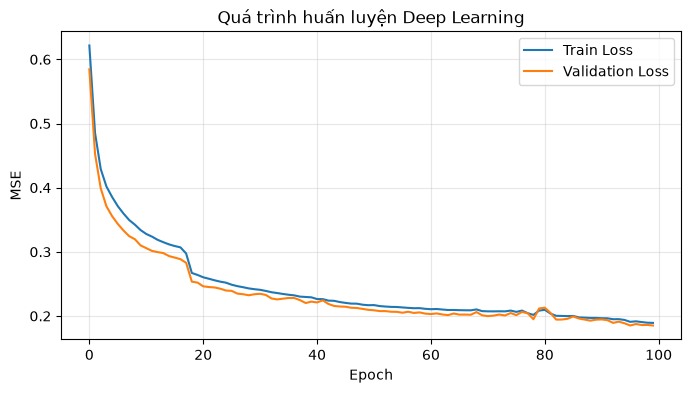

In [14]:
plt.figure(figsize=(8, 4))

plt.plot(train_loss_history, label="Train Loss")
plt.plot(val_loss_history, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Quá trình huấn luyện Deep Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** Train Loss giảm từ khoảng **0,6216** xuống **0,1892**, còn Validation Loss giảm từ khoảng **0,5845** xuống **0,1850**. Hai đường nhìn chung cùng giảm nên mạng đang học được từ dữ liệu. Validation Loss có dao động nhẹ ở một vài giai đoạn nhưng cuối cùng vẫn giảm, vì vậy chưa thấy dấu hiệu overfitting rõ ràng trong 100 epoch này.

### 10.6. Đánh giá Deep Learning

In [15]:
dl_pred_scaled, *_ = forward(X_val_scaled)

# Đổi về đơn vị tỷ VND
dl_pred = dl_pred_scaled.ravel() * y_std + y_mean

results.append(
    evaluate_model(
        "Deep Learning NumPy",
        y_val,
        dl_pred
    )
)

predictions["Deep Learning NumPy"] = dl_pred

display(pd.DataFrame([results[-1]]).round(4))

,Model,MAE,MSE,RMSE,R2
0,Deep Learning NumPy,1.0859,6.2447,2.4989,0.8065


## 11. So sánh 4 mô hình

Bốn mô hình được so sánh bằng **MAE, MSE, RMSE và R²**.

- **MAE**: càng thấp càng tốt.
- **MSE**: càng thấp càng tốt; nhạy với các sai số lớn vì sai số được bình phương.
- **RMSE**: càng thấp càng tốt; cùng đơn vị với giá nhà.
- **R²**: càng cao càng tốt.

Không nên chỉ nhìn một chỉ số. MAE dễ diễn giải, MSE nhấn mạnh các dự đoán sai lớn, còn R² cho biết mô hình giải thích được bao nhiêu biến thiên của giá.

In [16]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    "MAE",
    ascending=True
).reset_index(drop=True)

display(
    comparison_df.style
    .format({
        "MAE": "{:.4f}",
        "MSE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
)

,Model,MAE,MSE,RMSE,R2
0,Random Forest,0.8400,5.0970,2.2576,0.8421
1,Decision Tree,0.8951,5.7106,2.3897,0.8231
2,Deep Learning NumPy,1.0859,6.2447,2.4989,0.8065
3,Linear Regression,1.4771,9.4281,3.0705,0.7079


### Nhận xét kết quả so sánh

Trong lần chạy này, cần xem đồng thời **MAE, MSE, RMSE và R²**.

- Mô hình có MAE, MSE và RMSE thấp hơn sẽ có sai số dự đoán nhỏ hơn.
- MSE đặc biệt nhạy với các trường hợp dự đoán sai rất lớn.
- R² cao hơn cho thấy mô hình giải thích biến thiên của giá tốt hơn.
- Deep Learning không mặc định tốt hơn Machine Learning truyền thống; kết quả phụ thuộc dữ liệu và cấu hình mô hình.

### 11.1. Biểu đồ MAE và RMSE

Cột thấp hơn cho thấy sai số nhỏ hơn.

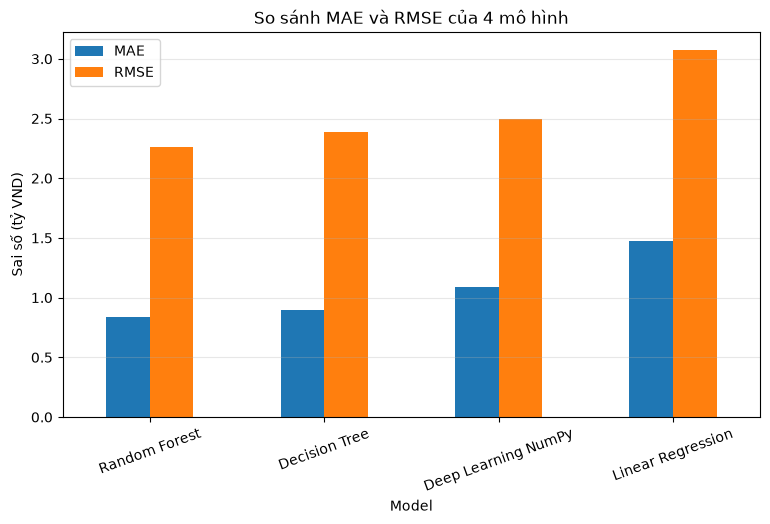

In [17]:
plot_df = comparison_df.set_index("Model")[["MAE", "RMSE"]]

plot_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Sai số (tỷ VND)")
plt.title("So sánh MAE và RMSE của 4 mô hình")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** **Random Forest** có MAE và RMSE thấp nhất trên Validation Set, lần lượt khoảng **0,8399** và **2,2573 tỷ VND**, nên có sai số tổng thể tốt nhất trong 4 mô hình. Decision Tree đứng thứ hai. Deep Learning NumPy tốt hơn Linear Regression nhưng vẫn chưa vượt Random Forest ở hai chỉ số này.

### 11.2. Biểu đồ MSE

MSE được vẽ riêng vì đơn vị là **(tỷ VND)²**, khác với MAE và RMSE.

Cột MSE càng thấp cho thấy mô hình có ít sai số lớn hơn.

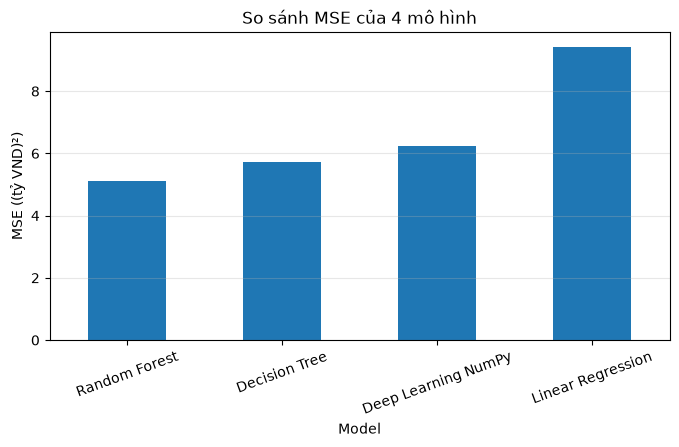

In [18]:
comparison_df.set_index("Model")["MSE"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.ylabel("MSE ((tỷ VND)²)")
plt.title("So sánh MSE của 4 mô hình")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** **Random Forest** có MSE thấp nhất, khoảng **5,0956**, tiếp theo là Decision Tree khoảng **5,7107**, Deep Learning NumPy khoảng **6,2400** và Linear Regression khoảng **9,4282**. Vì MSE bình phương sai số, giá trị thấp hơn cho thấy mô hình ít bị ảnh hưởng bởi các dự đoán sai lớn hơn.

### 11.3. Biểu đồ R²

R² càng cao thì mô hình giải thích biến thiên của giá nhà càng tốt.

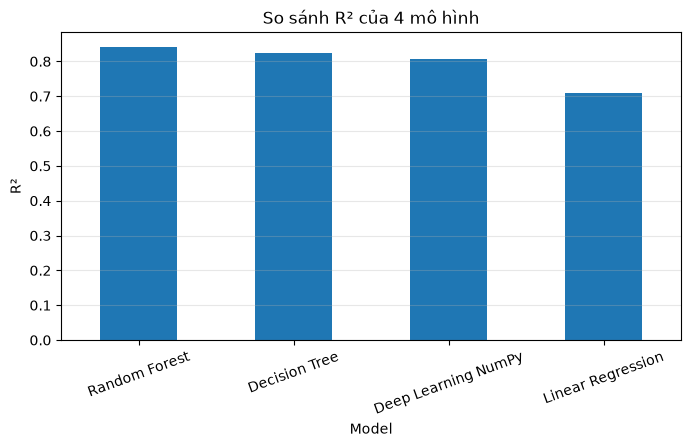

In [19]:
comparison_df.set_index("Model")["R2"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.ylabel("R²")
plt.title("So sánh R² của 4 mô hình")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** **Random Forest** có R² cao nhất, khoảng **0,8421**, nghĩa là mô hình giải thích được phần lớn biến thiên của giá trên Validation Set. Decision Tree đạt khoảng **0,8231**, Deep Learning NumPy khoảng **0,8067**, còn Linear Regression thấp nhất với khoảng **0,7079**.

## 12. Chọn mô hình tốt nhất trên Validation Set

Ở đây ta chọn mô hình có **MAE nhỏ nhất** trên Validation Set.

In [20]:
best_name = comparison_df.iloc[0]["Model"]

print("Mô hình tốt nhất theo Validation MAE:", best_name)
display(comparison_df.iloc[[0]])

Mô hình tốt nhất theo Validation MAE: Random Forest


,Model,MAE,MSE,RMSE,R2
0,Random Forest,0.840014,5.096972,2.257647,0.842075


## 13. Đánh giá mô hình tốt nhất trên Test Set

Sau khi đã chọn mô hình bằng Validation Set, ta mới dùng Test Set để đánh giá cuối cùng.

In [21]:
if best_name == "Deep Learning NumPy":
    test_scaled, *_ = forward(X_test_scaled)
    test_pred = test_scaled.ravel() * y_std + y_mean
else:
    test_pred = models[best_name].predict(X_test_scaled)

test_result = evaluate_model(
    best_name,
    y_test,
    test_pred
)

display(pd.DataFrame([test_result]).round(4))

,Model,MAE,MSE,RMSE,R2
0,Random Forest,0.8434,4.7876,2.1881,0.855


### Nhận xét trên Test Set

Mô hình được chọn là **Random Forest**. Trên Test Set, mô hình đạt:

- MAE khoảng **0,84 tỷ VND**
- RMSE khoảng **2,19 tỷ VND**
- R² khoảng **0,855**

MAE cho biết trung bình dự đoán lệch khoảng 0,84 tỷ VND. RMSE lớn hơn MAE cho thấy vẫn tồn tại một số căn nhà có sai số khá lớn. R² = 0,855 nghĩa là mô hình giải thích được phần lớn biến thiên của giá trong tập dữ liệu này, nhưng chưa thể xem là hệ thống định giá thực tế.

### 13.1. Biểu đồ Giá thực tế và Giá dự đoán

Nếu mô hình dự đoán tốt, các điểm sẽ nằm gần đường chéo `y = x`.

Các điểm nằm xa đường chéo là những căn nhà mà mô hình dự đoán sai nhiều.

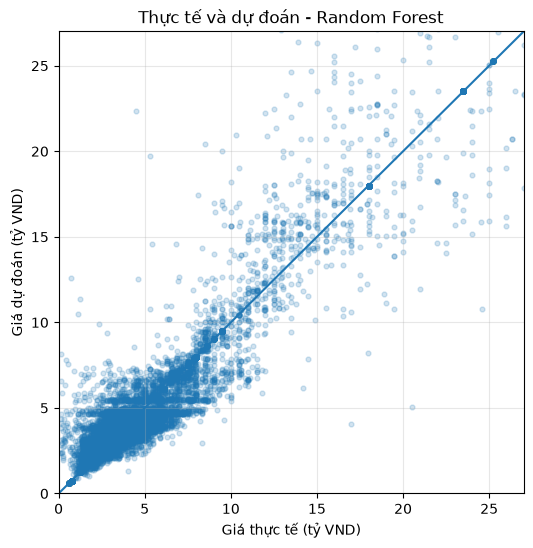

In [22]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    test_pred,
    alpha=0.2,
    s=12
)

limit = min(
    np.percentile(y_test, 99),
    np.percentile(test_pred, 99)
)

plt.plot([0, limit], [0, limit])

plt.xlim(0, limit)
plt.ylim(0, limit)

plt.xlabel("Giá thực tế (tỷ VND)")
plt.ylabel("Giá dự đoán (tỷ VND)")
plt.title(f"Thực tế và dự đoán - {best_name}")
plt.grid(alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** Mô hình được chọn là **Random Forest**. Các điểm càng nằm gần đường chéo thì giá dự đoán càng gần giá thực tế. Trên Test Set, mô hình đạt **MAE ≈ 0,8434 tỷ VND**, **MSE ≈ 4,7878**, **RMSE ≈ 2,1881 tỷ VND** và **R² ≈ 0,8550**. Kết quả cho thấy mô hình dự đoán khá tốt trên tập kiểm tra, nhưng vẫn còn một số trường hợp có sai số lớn.

## 14. Phân tích lỗi

Ta xem một số căn nhà có sai số lớn nhất.

Sai số tuyệt đối:

$$
Error = |y-\hat{y}|
$$

In [23]:
error_df = pd.DataFrame({
    "Giá thực tế": y_test,
    "Giá dự đoán": test_pred
})

error_df["Sai số tuyệt đối"] = abs(
    error_df["Giá thực tế"] - error_df["Giá dự đoán"]
)

display(
    error_df
    .sort_values("Sai số tuyệt đối", ascending=False)
    .head(10)
    .round(3)
)

,Giá thực tế,Giá dự đoán,Sai số tuyệt đối
14183,72.000,18.484,53.516
7518,79.890,28.322,51.569
5112,82.000,30.693,51.307
6740,99.000,48.666,50.334
6985,100.000,50.560,49.440
13990,65.000,26.430,38.570
1785,90.001,53.622,36.379
9943,65.000,30.406,34.594
7736,46.500,13.330,33.169
12824,50.000,18.357,31.643
